In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from dateutil import parser

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, confusion_matrix, accuracy_score, classification_report, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay

In [ ]:
path = kagglehub.dataset_download("fatihb/coffee-quality-data-cqi")

print("Path to dataset files:", path)

# Cargar el dataset de kaggle
df = pd.read_csv(path + "/df_arabica_clean.csv")

100%|██████████| 21.8k/21.8k [00:00<00:00, 26.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/fatihb/coffee-quality-data-cqi/versions/1


In [ ]:
df.head()

,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,...,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",...,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,...,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,...,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",...,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",...,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


#Preprocesado, limpieza, estandarización, etc

In [ ]:
# manejar duplicados
duplicate_rows_data = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_data.shape)

number of duplicate rows:  (0, 41)


In [ ]:
#contar valores únicos
for column in df.columns:
    num_distinct_values = len(df[column].unique())
    print(f"{column}: {num_distinct_values} distinct values")

Unnamed: 0: 207 distinct values
ID: 207 distinct values
Country of Origin: 22 distinct values
Farm Name: 173 distinct values
Lot Number: 188 distinct values
Mill: 163 distinct values
ICO Number: 68 distinct values
Company: 72 distinct values
Altitude: 98 distinct values
Region: 121 distinct values
Producer: 173 distinct values
Number of Bags: 55 distinct values
Bag Weight: 39 distinct values
In-Country Partner: 21 distinct values
Harvest Year: 7 distinct values
Grading Date: 75 distinct values
Owner: 80 distinct values
Variety: 49 distinct values
Status: 1 distinct values
Processing Method: 11 distinct values
Aroma: 19 distinct values
Flavor: 19 distinct values
Aftertaste: 20 distinct values
Acidity: 19 distinct values
Body: 17 distinct values
Balance: 18 distinct values
Uniformity: 3 distinct values
Clean Cup: 1 distinct values
Sweetness: 1 distinct values
Overall: 21 distinct values
Defects: 1 distinct values
Total Cup Points: 81 distinct values
Moisture Percentage: 46 distinct value

In [ ]:
#ver ratio de faltantes
data_na = (df.isnull().sum() / len(df)) * 100
data_na = data_na.drop(data_na[data_na == 0].index).sort_values(ascending=False)[:30]
missing_data = pd.DataFrame({'Missing Ratio' :data_na})
missing_data.head(20)

,Missing Ratio
ICO Number,63.768116
Variety,2.898551
Processing Method,2.415459
Mill,1.449275
Farm Name,0.966184
Region,0.966184
Lot Number,0.483092
Altitude,0.483092
Producer,0.483092


In [ ]:
# Mapeo del método de procesamiento
processing_mapping = {
    "Double Anaerobic Washed": "Washed / Wet",
    "Semi Washed": "Washed / Wet",
    "Honey,Mossto": "Pulped natural / honey",
    "Double Carbonic Maceration / Natural": "Natural / Dry",
    "Wet Hulling": "Washed / Wet",
    "Anaerobico 1000h": "Washed / Wet",
    "SEMI-LAVADO": "Natural / Dry"
}

# corergir valores mapeando
df['Processing Method'] = df['Processing Method'].map(processing_mapping)

#vacíos
df['Processing Method'] = df['Processing Method'].fillna("Washed / Wet")


In [ ]:
df.head()

,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,...,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",...,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,...,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,...,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",...,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",...,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


In [ ]:
print(df.loc[df['ID'].isin([99, 105, 180]), ['ID', 'Altitude']])

      ID     Altitude
99    99  4895 A 5650
105  105          NaN
180  180    1200~1600


In [ ]:
df[df.columns[df.isnull().any()]].isnull().sum()

,0
Farm Name,2
Lot Number,1
Mill,3
ICO Number,132
Altitude,1
Region,2
Producer,1
Variety,6


In [ ]:
# Detectar valores raros con regex
weird_altitudes = df[df['Altitude'].astype(str).str.contains(r'[^\d\.]', regex=True)]
print(weird_altitudes[['Altitude']])

        Altitude
0      1700-1930
4      1850-2100
9      1400-1700
10     1800-2200
13     1900-2000
16     1900-2100
19     1570-1600
22     1500-1700
30       150-250
31       150-250
34   2150 - 2350
38     1600-1900
40       300-500
49       350-400
62       200-300
74     1300-1400
79     1250-1350
86     1500-1600
87     1500-1600
89     1600-1750
91     1400-1700
92     1400-1700
96     1300-1400
99   4895 A 5650
102      400-600
105          NaN
108      200-400
110      250-400
111      250-300
115  1200 - 1580
118  1400 - 1900
121      200-300
122    1280-1325
127    1300-1500
128    1400-1700
130    1100-1200
134      200-300
136  1200 - 1300
140      250-300
145    1300-1500
150  1200 - 1580
163    1200-1350
170    1500-1950
175     800-1200
177    1350-1550
180    1200~1600
184     900-1000
190    1300-1500
192      600-800
193    1300-1800
206     850-1100


In [ ]:
df.loc[df['ID'] == 99, 'Altitude'] = 5273  # Impute value for ID 99
df.loc[df['ID'] == 105, 'Altitude'] = 1800  # Impute value for ID 105
df.loc[df['ID'] == 180, 'Altitude'] = 1400  # Impute value for ID 180

def clean_altitude_range(range_value):
    if isinstance(range_value, str):  # Verifica si es un string
        range_value = range_value.replace(" ", "")  # Elimina espacios en blanco

        if '-' in range_value:  # Si el valor tiene un rango (ejemplo: "1500-1800")
            try:
                start, end = range_value.split('-')  # Separa el rango en dos valores
                start = int(start)  # Convierte a entero
                end = int(end)
                return (start + end) / 2  # Calcula el promedio
            except ValueError:
                return np.nan  # Si falla la conversión, devuelve NaN (valor nulo)

        else:  # Si no tiene un rango, intenta convertirlo en entero
            try:
                return int(range_value)
            except ValueError:
                return np.nan  # Si falla la conversión, devuelve NaN

    else:  # Si el valor no es un string, lo devuelve sin cambios
        return range_value

In [ ]:

df['Altitude'] = df['Altitude'].apply(clean_altitude_range)

# 2. Imputa valores específicos si los conoces (opcional)
df.loc[df['ID'] == 99, 'Altitude'] = 5273
df.loc[df['ID'] == 105, 'Altitude'] = 1800
df.loc[df['ID'] == 180, 'Altitude'] = 1400

print("Valores faltantes antes de imputar:", df['Altitude'].isna().sum())

imputer = SimpleImputer(strategy='mean')
altitude_imputed = imputer.fit_transform(df[['Altitude']])
df['Altitude'] = altitude_imputed

print("Valores faltantes después de imputar:", df['Altitude'].isna().sum())


Valores faltantes antes de imputar: 0
Valores faltantes después de imputar: 0


In [ ]:
# Extract the prior year from the "Harvest Year" column
df['Harvest Year'] = df['Harvest Year'].str.split('/').str[0].str.strip()

In [ ]:
# Convert "Harvest Year" and "Expiration" columns to datetime objects using dateutil parser
df['Harvest Year'] = pd.to_datetime(df['Harvest Year'], format='%Y')
df['Expiration'] = df['Expiration'].apply(parser.parse)

In [ ]:
# Calculate the difference in days between "Expiration" and "Harvest Year" columns
df['Coffee Age'] = (df['Expiration'] - df['Harvest Year']).dt.days

In [ ]:
#dropear datos que no aportan(vacíos, irrelevantes)
columns_to_drop = ['ID','ICO Number','Owner','Region','Certification Contact','Certification Address','Farm Name',"Lot Number","Mill","ICO Number","Producer",'Company','Expiration', 'Harvest Year', "Unnamed: 0",'Number of Bags','Bag Weight','In-Country Partner','Grading Date','Variety','Status','Defects','Uniformity','Clean Cup','Sweetness','Certification Body']
df.drop(columns_to_drop, axis=1, inplace=True)

In [ ]:
df.head()

,Country of Origin,Altitude,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Overall,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Coffee Age
0,Colombia,1815.0,Washed / Wet,8.58,8.50,8.42,8.58,8.25,8.42,8.58,89.33,11.8,0,0,green,3,993
1,Taiwan,1200.0,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,8.50,87.58,10.5,0,0,blue-green,0,1048
2,Laos,1300.0,Washed / Wet,8.33,8.42,8.08,8.17,7.92,8.17,8.33,87.42,10.4,0,0,yellowish,2,1048
3,Costa Rica,1900.0,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,8.25,87.17,11.8,0,0,green,0,628
4,Colombia,1975.0,Pulped natural / honey,8.33,8.33,8.08,8.25,7.92,7.92,8.25,87.08,11.6,0,2,yellow-green,2,794


# **Pre Análisis**

In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country of Origin     207 non-null    object 
 1   Altitude              207 non-null    float64
 2   Processing Method     207 non-null    object 
 3   Aroma                 207 non-null    float64
 4   Flavor                207 non-null    float64
 5   Aftertaste            207 non-null    float64
 6   Acidity               207 non-null    float64
 7   Body                  207 non-null    float64
 8   Balance               207 non-null    float64
 9   Overall               207 non-null    float64
 10  Total Cup Points      207 non-null    float64
 11  Moisture Percentage   207 non-null    float64
 12  Category One Defects  207 non-null    int64  
 13  Quakers               207 non-null    int64  
 14  Color                 207 non-null    object 
 15  Category Two Defects  2

In [ ]:
df.describe()

,Altitude,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Overall,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Category Two Defects,Coffee Age
count,207.000000,207.000000,207.000000,207.000000,207.00000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean,1314.099034,7.721063,7.744734,7.599758,7.69029,7.640918,7.644058,7.676812,83.706570,10.735266,0.135266,0.690821,2.251208,893.565217
std,720.564046,0.287626,0.279613,0.275911,0.25951,0.233499,0.256299,0.306359,1.730417,1.247468,0.592070,1.686918,2.950183,234.373891
min,139.000000,6.500000,6.750000,6.670000,6.83000,6.830000,6.670000,6.670000,78.000000,0.000000,0.000000,0.000000,0.000000,431.000000
25%,1020.000000,7.580000,7.580000,7.420000,7.50000,7.500000,7.500000,7.500000,82.580000,10.100000,0.000000,0.000000,0.000000,753.000000
50%,1340.000000,7.670000,7.750000,7.580000,7.67000,7.670000,7.670000,7.670000,83.750000,10.800000,0.000000,0.000000,1.000000,880.000000
75%,1600.000000,7.920000,7.920000,7.750000,7.87500,7.750000,7.790000,7.920000,84.830000,11.500000,0.000000,1.000000,3.000000,1048.000000
max,5400.000000,8.580000,8.500000,8.420000,8.58000,8.250000,8.420000,8.580000,89.330000,13.500000,5.000000,12.000000,16.000000,2487.000000


In [ ]:
num_columns = df.select_dtypes(include=['number']).columns.tolist()
print(num_columns)

['Altitude', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Overall', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Category Two Defects', 'Coffee Age']


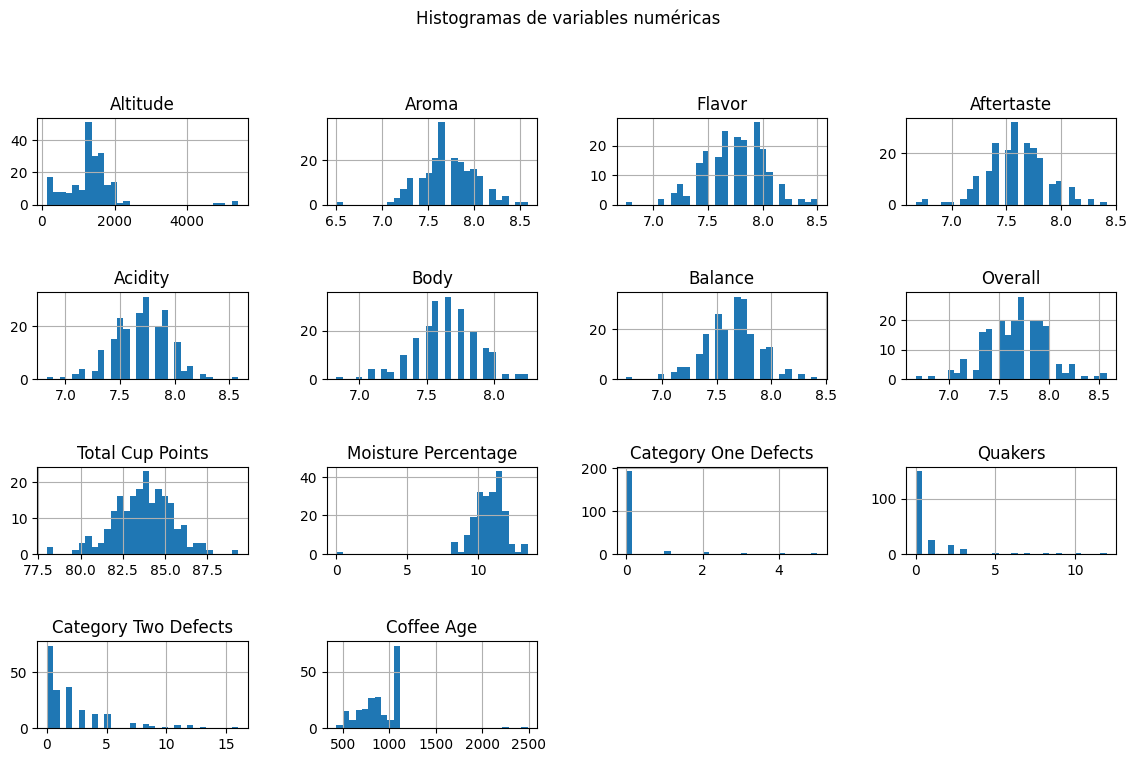

In [ ]:
df[num_columns].hist(figsize=(12, 8), bins=30)
plt.suptitle('Histogramas de variables numéricas')
plt.tight_layout(pad=3)
plt.show()

In [ ]:
cat_columns = df.select_dtypes(include=['object']).columns.tolist()
print(cat_columns)

['Country of Origin', 'Processing Method', 'Color']


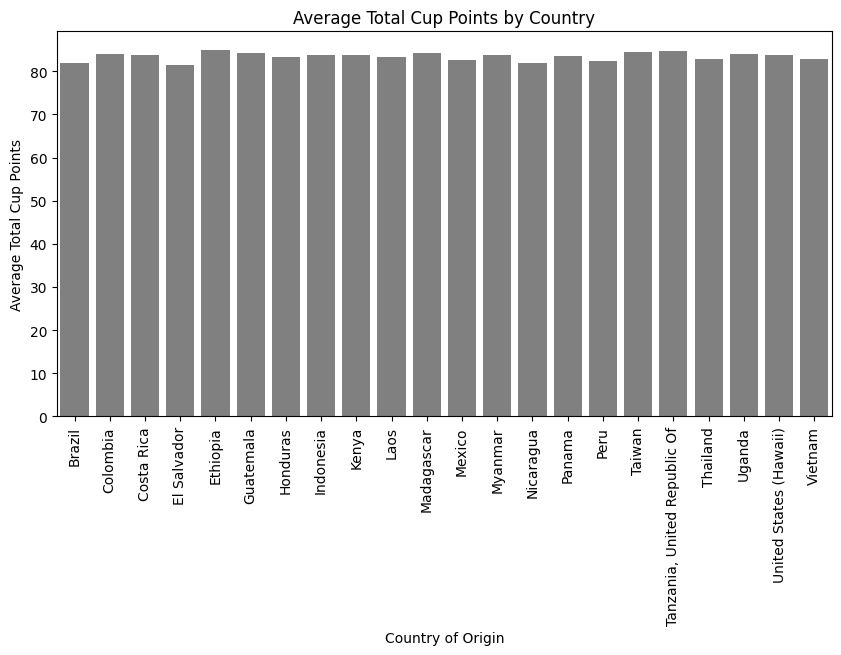

In [ ]:
# Create a bar plot with gray color

df_grouped = df.groupby('Country of Origin')['Total Cup Points'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=df_grouped['Country of Origin'], y=df_grouped['Total Cup Points'], color='gray')
plt.title('Average Total Cup Points by Country')
plt.xlabel('Country of Origin')
plt.ylabel('Average Total Cup Points')
plt.xticks(rotation=90)
plt.show()

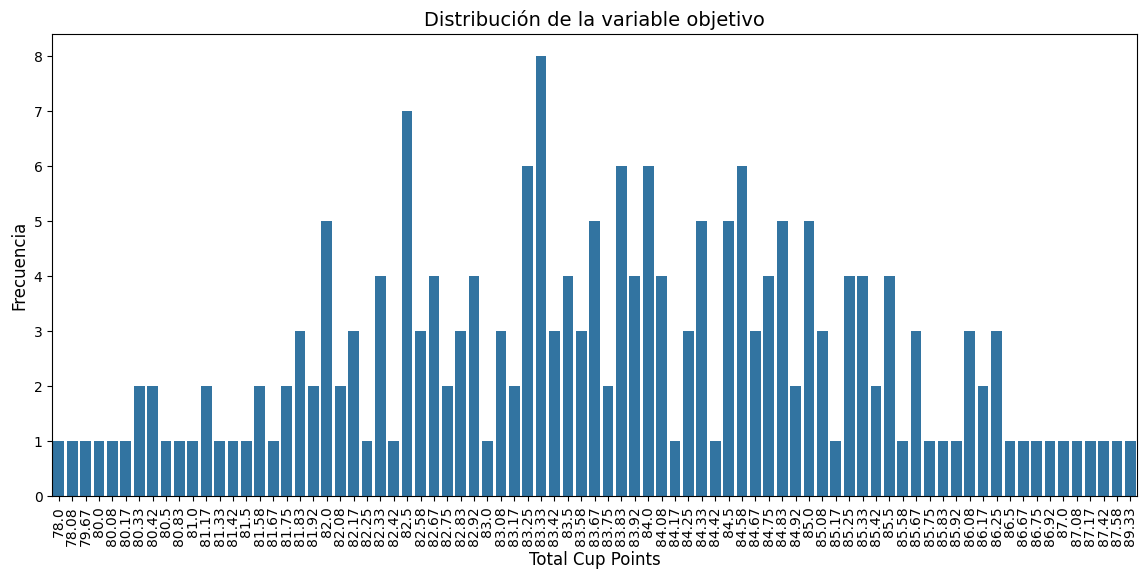

In [ ]:
plt.figure(figsize=(14, 6))
sns.countplot(x=df['Total Cup Points'])
plt.title('Distribución de la variable objetivo', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.xlabel('Total Cup Points', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.show()


In [ ]:
df['Altitude'] = pd.to_numeric(df['Altitude'], errors='coerce')
print(df[['Altitude', 'Total Cup Points']].dtypes)

Altitude            float64
Total Cup Points    float64
dtype: object


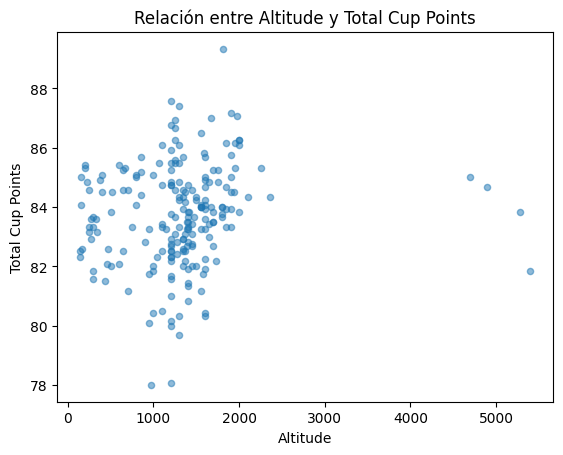

In [ ]:
df.plot.scatter(x='Altitude', y='Total Cup Points', alpha=0.5)
plt.title("Relación entre Altitude y Total Cup Points")
plt.show()

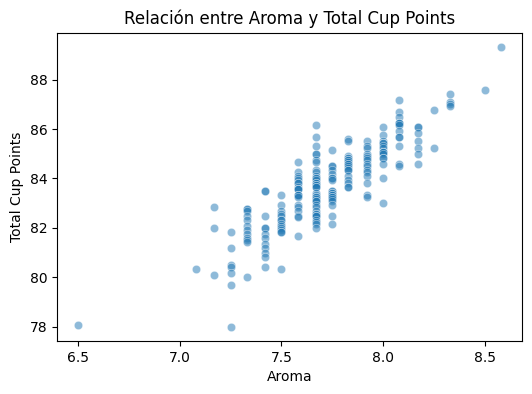

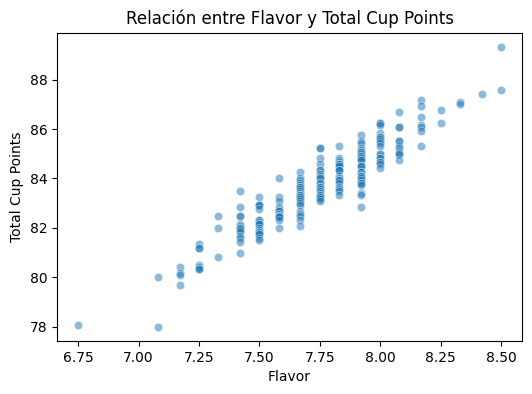

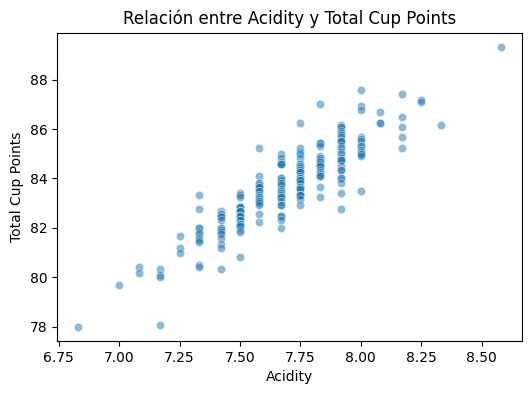

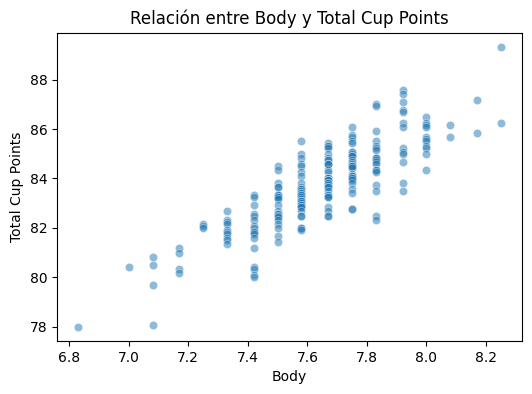

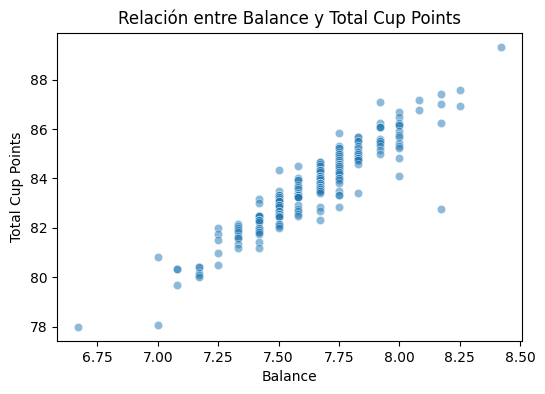

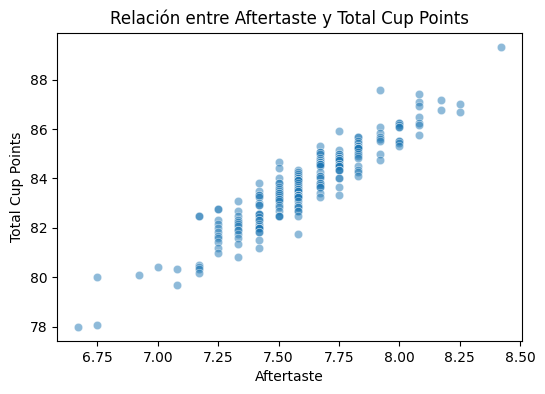

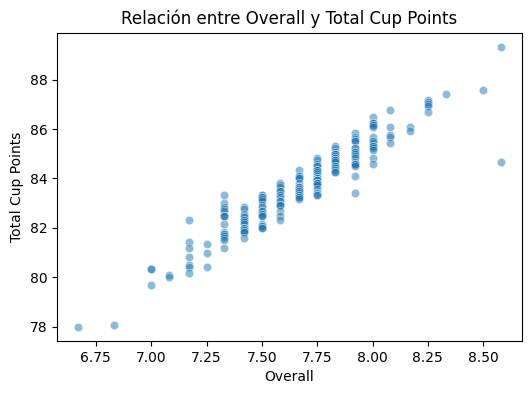

In [ ]:
sensorial_features = ['Aroma', 'Flavor', 'Acidity', 'Body', 'Balance', 'Aftertaste', 'Overall']

for feature in sensorial_features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[feature], y=df['Total Cup Points'], alpha=0.5)
    plt.title(f'Relación entre {feature} y Total Cup Points')
    plt.show()


#Encoding, normalización

In [ ]:
data = df.copy()
categorical_columns = ['Processing Method']
numerical_columns = ['Altitude', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Overall', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Category Two Defects', 'Coffee Age']
columns_to_drop = ['Country of Origin', 'Color']
data.drop(columns_to_drop, axis=1, inplace=True)

In [ ]:
dummy_variables = pd.get_dummies(data, columns=categorical_columns, drop_first=False)

In [ ]:
#Codificamos variables categóricas con One-Hot Encoding
data_encoded = pd.get_dummies(data, columns=categorical_columns, drop_first=False)

In [ ]:
#Normalizamos variables numéricas
scaler = StandardScaler()
scaled_numerical = scaler.fit_transform(data[numerical_columns])
scaled_numerical_df = pd.DataFrame(scaled_numerical, columns=numerical_columns)

In [ ]:
# Eliminamos las columnas numéricas originales de data_encoded
data_encoded = data_encoded.drop(columns=numerical_columns, axis=1)

# Concatenamos variables codificadas y numéricas escaladas
processed_df = pd.concat([data_encoded, scaled_numerical_df], axis=1)

In [ ]:
#Matriz de correlación completa
correlation_matrix = processed_df.corr()

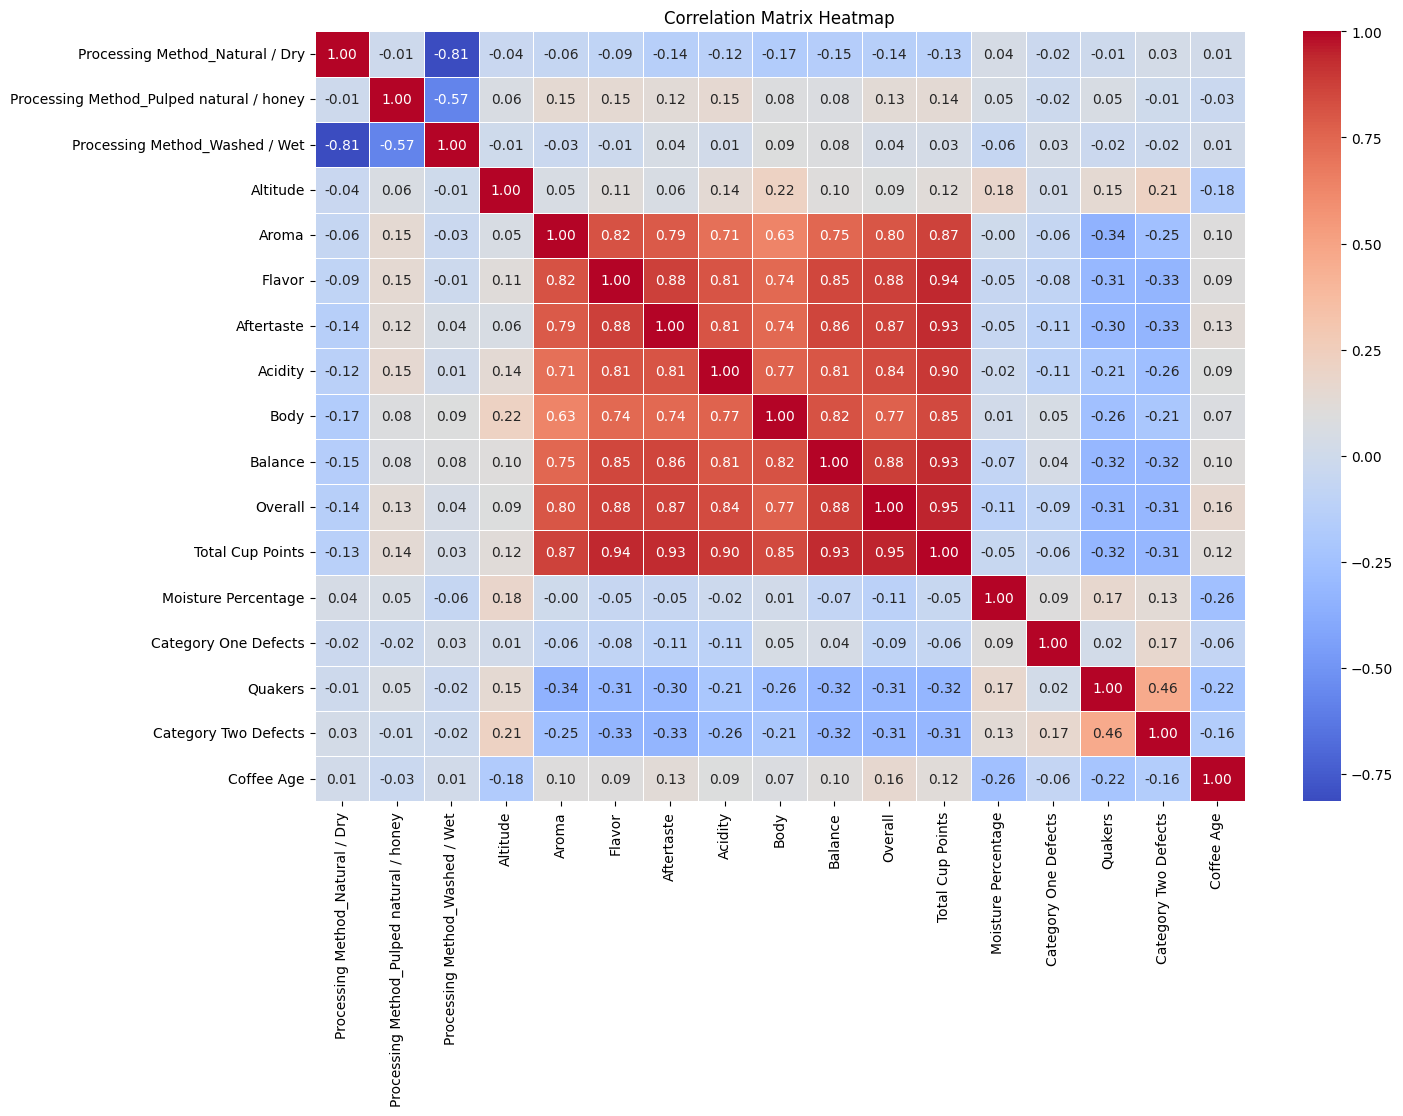

In [ ]:
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
#Correlación con la variable target
target_corr = correlation_matrix['Total Cup Points'].drop('Total Cup Points')
target_corr_sorted = target_corr.sort_values(ascending=False)

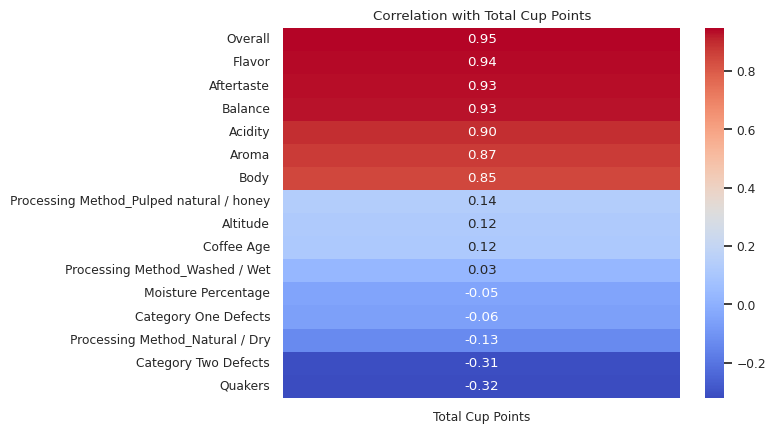

In [ ]:
# Gráfico II: Solo correlación con la variable objetivo
sns.set(font_scale=0.8)
sns.set_style("white")
sns.heatmap(target_corr_sorted.to_frame(), cmap="coolwarm", annot=True, fmt='.2f')
plt.title('Correlation with Total Cup Points')
plt.show()

# Preprocesamiento y Entrenamiento

In [ ]:
X = processed_df.drop(columns=['Total Cup Points'])
y = processed_df['Total Cup Points']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Modelos y pipelines

In [ ]:
rf_base = RandomForestRegressor(random_state=42)
gb_base = GradientBoostingRegressor(random_state=42)
et_base = ExtraTreesRegressor(random_state=42)

pipeline_rf = Pipeline([('regressor', rf_base)])
pipeline_gb = Pipeline([('regressor', gb_base)])
pipeline_et = Pipeline([('regressor', et_base)])

Malla de hiperparámetros para el gridsearch

In [ ]:
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [5, 10, None],
    'regressor__min_samples_split': [2, 10],
    'regressor__min_samples_leaf': [1, 4]
}

rf = GridSearchCV(pipeline_rf, param_grid=param_grid, cv=3, n_jobs=-1)
gb = GridSearchCV(pipeline_gb, param_grid=param_grid, cv=3, n_jobs=-1)
et = GridSearchCV(pipeline_et, param_grid=param_grid, cv=3, n_jobs=-1)

Entrenamiento

In [ ]:
rf.fit(X_train, y_train) #este es random forest
gb.fit(X_train, y_train) #este es gradient boosting
et.fit(X_train, y_train) #este es extra trees

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('regressor',
                                        ExtraTreesRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'regressor__max_depth': [5, 10, None],
                         'regressor__min_samples_leaf': [1, 4],
                         'regressor__min_samples_split': [2, 10],
                         'regressor__n_estimators': [100, 200]})

#Evaluación de resultados

In [ ]:
models = {'Random Forest': rf, 'Gradient Boosting': gb, 'Extra Trees': et}

print("Train set")
for name, model in models.items():
    print(f"Model: {name}")
    print(f'R^2: {model.score(X_train, y_train)}')
    print(f'MAE: {mean_absolute_error(y_train, model.predict(X_train))}')
    print('\n')

print("Test set")
for name, model in models.items():
    print(f"Model: {name}")
    print(f'R^2: {model.score(X_test, y_test)}')
    print(f'MAE: {mean_absolute_error(y_test, model.predict(X_test))}')
    print('\n')

Train set
Model: Random Forest
R^2: 0.9940605238693389
MAE: 0.049335015020986986


Model: Gradient Boosting
R^2: 0.9999983672687793
MAE: 0.000980291032908768


Model: Extra Trees
R^2: 0.999951687827234
MAE: 0.0042773058232726795


Test set
Model: Random Forest
R^2: 0.9468443984638673
MAE: 0.12631438987114613


Model: Gradient Boosting
R^2: 0.955407170371647
MAE: 0.11365366733203806


Model: Extra Trees
R^2: 0.9659401765167948
MAE: 0.08118170311846871




In [ ]:
print("Mejor R² promedio en validación cruzada:")
print(f"Random Forest: {rf.best_score_:.4f}")
print(f"Gradient Boosting: {gb.best_score_:.4f}")
print(f"Extra Trees: {et.best_score_:.4f}")

Mejor R² promedio en validación cruzada:
Random Forest: 0.9602
Gradient Boosting: 0.9650
Extra Trees: 0.9687


#Predicciones

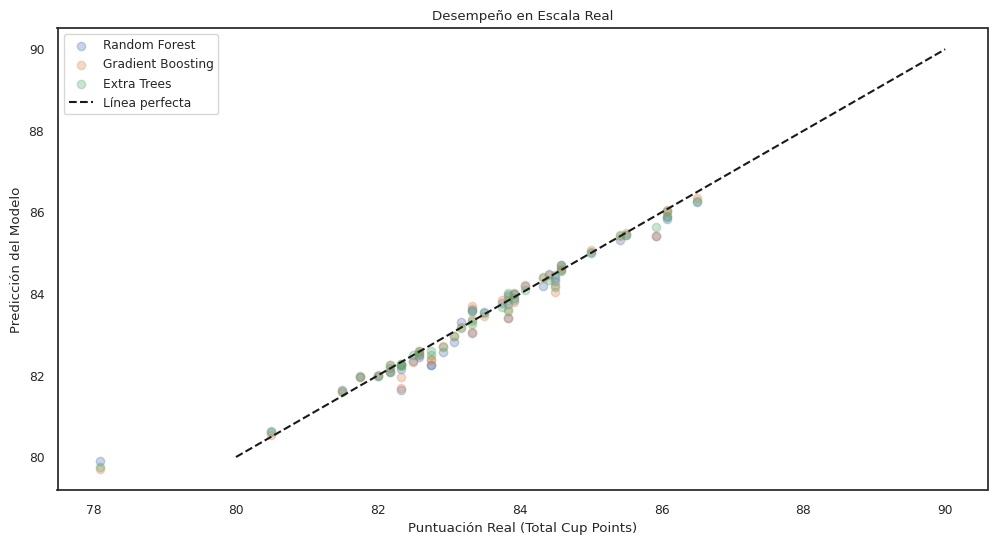


MAE en puntos reales:
- Random Forest: 0.22
- Gradient Boosting: 0.20
- Extra Trees: 0.14

R²:
- Random Forest: 0.95
- Gradient Boosting: 0.96
- Extra Trees: 0.97


In [ ]:
# Predicciones con el pipeline (normalizadas)
y_pred_rf = rf.predict(X_test)  # Random Forest
y_pred_gb = gb.predict(X_test)  # Gradient Boosting
y_pred_et = et.predict(X_test)  # Extra Trees

# Desnormalización
media = scaler.mean_[numerical_columns.index('Total Cup Points')]
std = scaler.scale_[numerical_columns.index('Total Cup Points')]

y_test_real = (y_test * std) + media
y_pred_rf_real = (y_pred_rf * std) + media
y_pred_gb_real = (y_pred_gb * std) + media
y_pred_et_real = (y_pred_et * std) + media

# Gráfico comparativo (escala original)
plt.figure(figsize=(12, 6))
plt.scatter(y_test_real, y_pred_rf_real, alpha=0.3, label='Random Forest')
plt.scatter(y_test_real, y_pred_gb_real, alpha=0.3, label='Gradient Boosting')
plt.scatter(y_test_real, y_pred_et_real, alpha=0.3, label='Extra Trees')
plt.plot([80, 90], [80, 90], 'k--', label='Línea perfecta')  # Rango típico
plt.xlabel("Puntuación Real (Total Cup Points)")
plt.ylabel("Predicción del Modelo")
plt.title("Desempeño en Escala Real")
plt.legend()
plt.show()

# Métricas en escala original
from sklearn.metrics import mean_absolute_error, r2_score

print("\nMAE en puntos reales:")
print(f"- Random Forest: {mean_absolute_error(y_test_real, y_pred_rf_real):.2f}")
print(f"- Gradient Boosting: {mean_absolute_error(y_test_real, y_pred_gb_real):.2f}")
print(f"- Extra Trees: {mean_absolute_error(y_test_real, y_pred_et_real):.2f}")

print("\nR²:")
print(f"- Random Forest: {r2_score(y_test_real, y_pred_rf_real):.2f}")
print(f"- Gradient Boosting: {r2_score(y_test_real, y_pred_gb_real):.2f}")
print(f"- Extra Trees: {r2_score(y_test_real, y_pred_et_real):.2f}")

#Explicabilidad

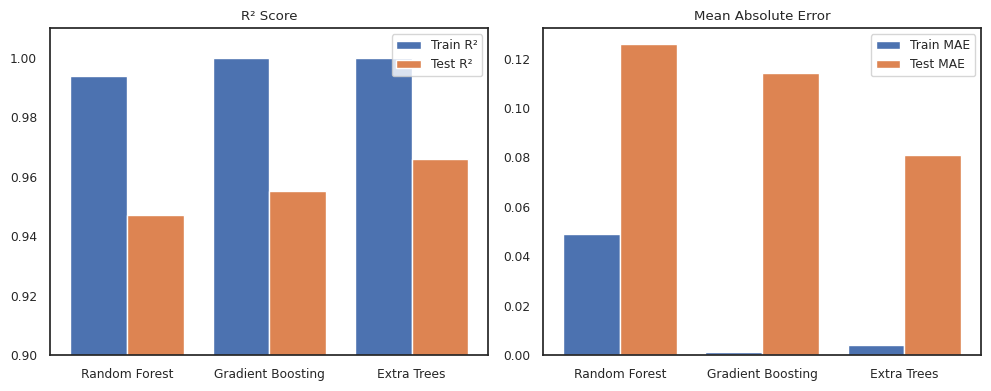

In [ ]:
models = ['Random Forest', 'Gradient Boosting', 'Extra Trees']
r2_train = [0.994, 0.999998, 0.99995]
r2_test = [0.947, 0.955, 0.966]
mae_train = [0.049, 0.001, 0.004]
mae_test = [0.126, 0.114, 0.081]

x = np.arange(len(models))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(x - 0.2, r2_train, 0.4, label='Train R²')
plt.bar(x + 0.2, r2_test, 0.4, label='Test R²')
plt.xticks(x, models)
plt.ylim(0.9, 1.01)
plt.title('R² Score')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(x - 0.2, mae_train, 0.4, label='Train MAE')
plt.bar(x + 0.2, mae_test, 0.4, label='Test MAE')
plt.xticks(x, models)
plt.title('Mean Absolute Error')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
!pip install shap

In [ ]:
import shap
from IPython.display import HTML

In [ ]:
# Entrenamos nuestro pipeline con los mejores parámetros encontrados en la validación cruzada
pipeline_rf.set_params(**rf.best_params_)
pipeline_rf.fit(X_train, y_train)

pipeline_gb.set_params(**gb.best_params_)
pipeline_gb.fit(X_train, y_train)

pipeline_et.set_params(**et.best_params_)
pipeline_et.fit(X_train, y_train)

Pipeline(steps=[('regressor',
                 ExtraTreesRegressor(max_depth=10, n_estimators=200,
                                     random_state=42))])

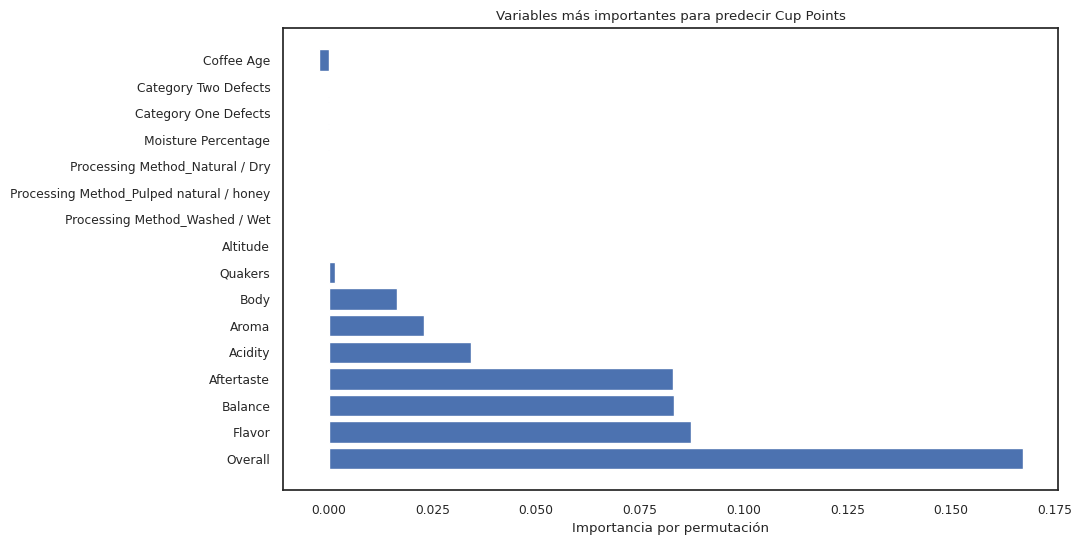

In [ ]:
from sklearn.inspection import permutation_importance

# Modelo ya entrenado (ej.: RandomForest o Lasso)
result = permutation_importance(et, X_test, y_test, n_repeats=10, random_state=42)

# Ordenar importancias
sorted_idx = result.importances_mean.argsort()[::-1]

# Gráfico
plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], result.importances_mean[sorted_idx])
plt.xlabel("Importancia por permutación")
plt.title("Variables más importantes para predecir Cup Points")
plt.show()

In [ ]:
# Entrenemos nuestro modelo de explicabilidad
rf_explainer = shap.TreeExplainer(pipeline_rf.named_steps["regressor"])
test_rf_shap_values = rf_explainer.shap_values(X_test)

gb_explainer = shap.TreeExplainer(pipeline_gb.named_steps["regressor"])
test_gb_shap_values = gb_explainer.shap_values(X_test)

et_explainer = shap.TreeExplainer(pipeline_et.named_steps["regressor"])
test_et_shap_values = et_explainer.shap_values(X_test)

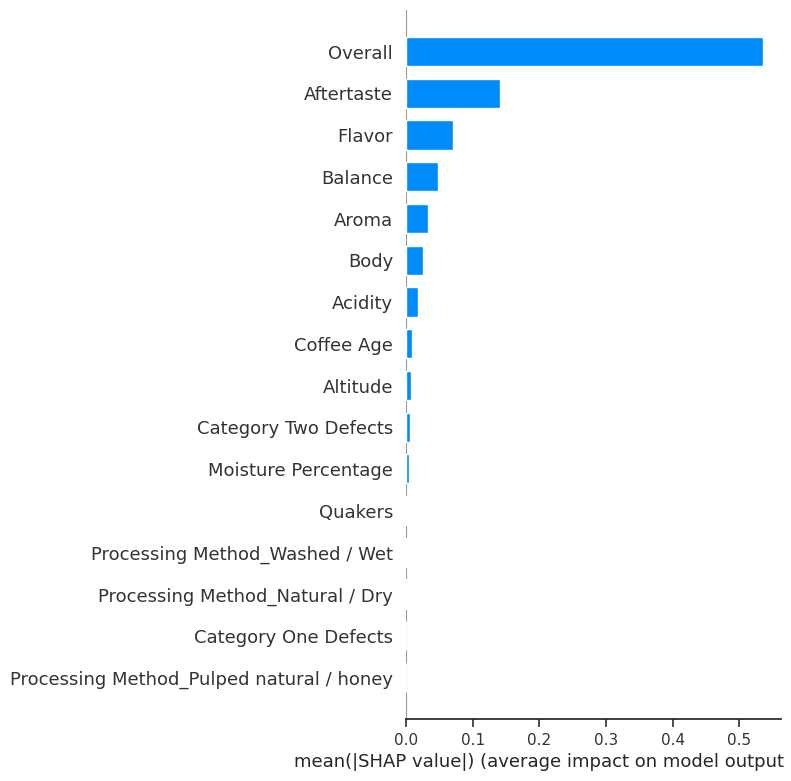

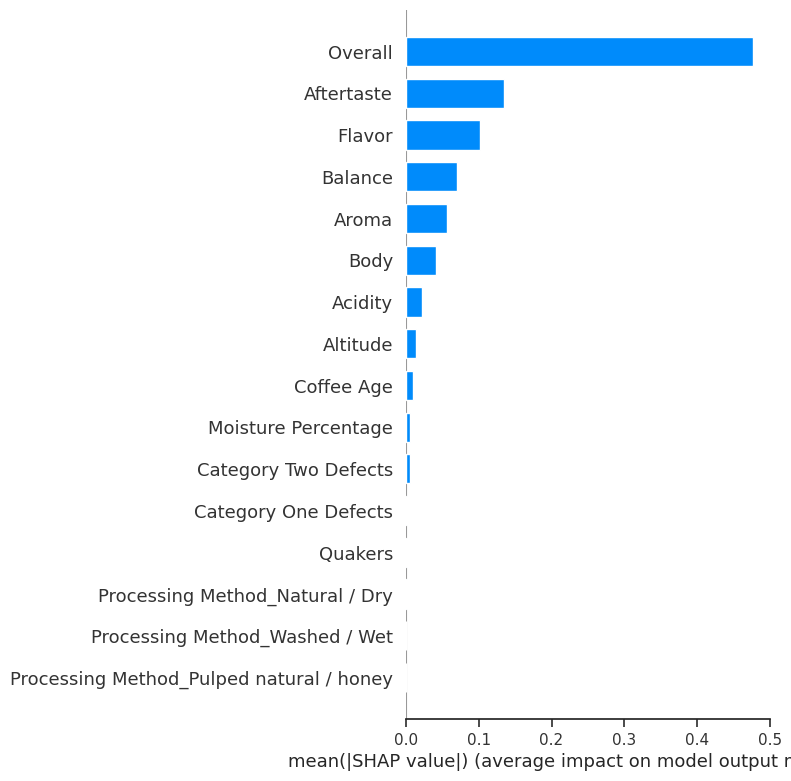

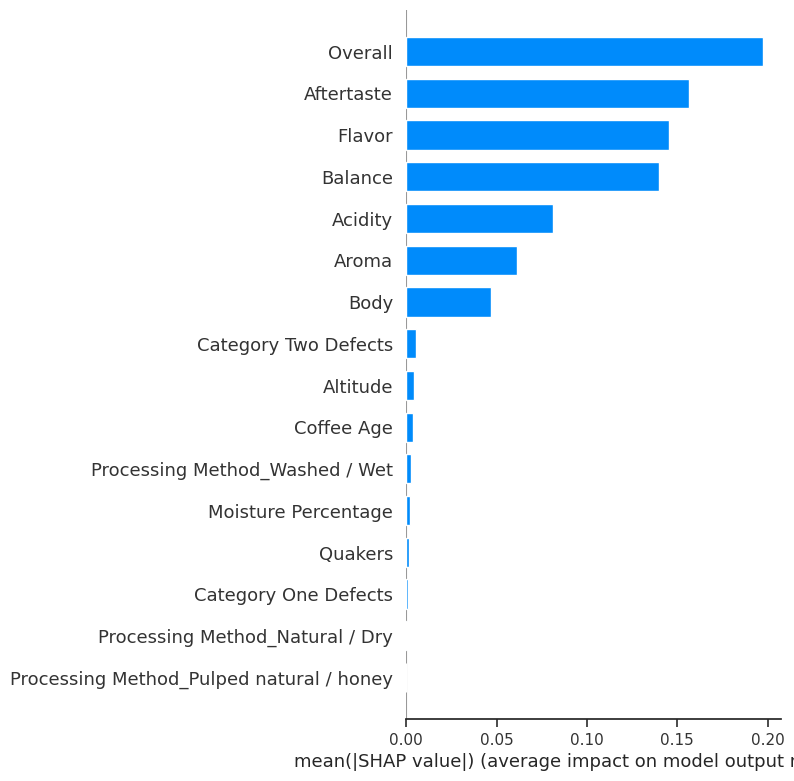

In [ ]:
# Summary plot
shap.summary_plot(test_rf_shap_values, X_test, plot_type="bar") #random forest
shap.summary_plot(test_gb_shap_values, X_test, plot_type="bar") #gradient boosting
shap.summary_plot(test_et_shap_values, X_test, plot_type="bar") #extra trees

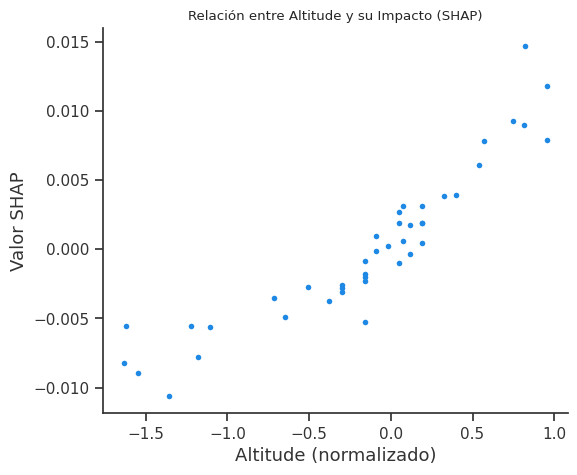

In [ ]:
altitude_idx = list(X_test.columns).index("Altitude")
shap.dependence_plot(
    ind=altitude_idx,                      # Índice de "Altitude"
    shap_values=test_et_shap_values,       # SHAP values
    features=X_test,                       # Datos de prueba
    feature_names=X_test.columns,          # Nombres de variables
    interaction_index=None,                # Sin interacción
    show=False
)
plt.title("Relación entre Altitude y su Impacto (SHAP)")
plt.xlabel("Altitude (normalizado)")
plt.ylabel("Valor SHAP")
plt.show()

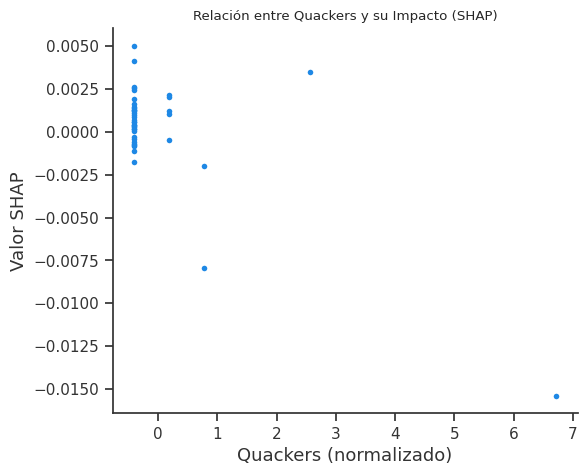

In [ ]:
quakers_idx = list(X_test.columns).index("Quakers")
shap.dependence_plot(
    ind=quakers_idx,                      # Índice de "Altitude"
    shap_values=test_et_shap_values,       # SHAP values
    features=X_test,                       # Datos de prueba
    feature_names=X_test.columns,          # Nombres de variables
    interaction_index=None,                # Sin interacción
    show=False
)
plt.title("Relación entre Quackers y su Impacto (SHAP)")
plt.xlabel("Quackers (normalizado)")
plt.ylabel("Valor SHAP")
plt.show()

=== Predicciones de Calidad ===


,Aroma,Flavor,Overall,Predicción Total Cup Points
0,-0.490000,-0.590000,-0.570000,-0.701949
1,1.560000,1.200000,1.050000,1.345572
2,2.500000,2.700000,2.900000,2.967289


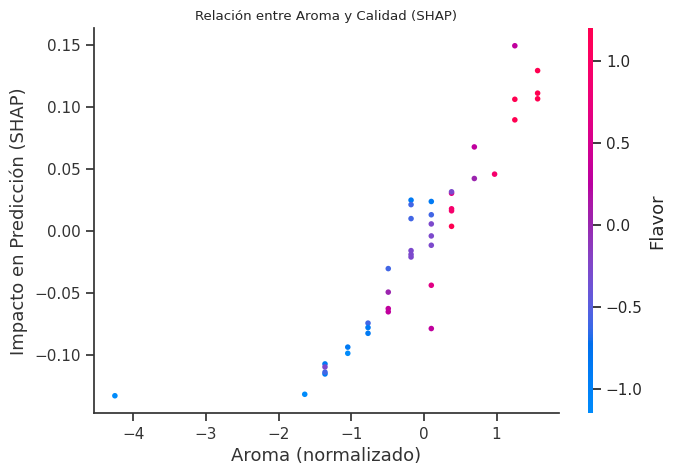

In [ ]:

from IPython.display import display

datos_demo = pd.DataFrame({
    "Processing Method_Natural / Dry": [False, False, False],
    "Processing Method_Pulped natural / honey": [False, True, False],
    "Processing Method_Washed / Wet": [True, False, True],
    "Altitude": [0.07, -0.29, 1.20],
    "Aroma": [-0.49, 1.56, 2.50],
    "Flavor": [-0.59, 1.20, 2.70],
    "Aftertaste": [-0.98, 1.45, 2.90],
    "Acidity": [-0.73, 0.88, 3.40],
    "Body": [-0.26, 1.54, 2.60],
    "Balance": [-0.87, 1.07, 3.00],
    "Overall": [-0.57, 1.05, 2.90],
    "Moisture Percentage": [-0.10, -0.43, 0.85],
    "Category One Defects": [-0.22, -0.22, -0.22],
    "Quakers": [-0.41, -0.41, 0.77],
    "Category Two Defects": [1.95, -0.76, -0.08],
    "Coffee Age": [-0.09, 0.66, -1.13]
})

predicciones = pipeline_et.predict(datos_demo)
datos_demo["Predicción Total Cup Points"] = predicciones

print("=== Predicciones de Calidad ===")
display(datos_demo[["Aroma", "Flavor", "Overall", "Predicción Total Cup Points"]].style
      .background_gradient(cmap="RdYlGn", subset=["Predicción Total Cup Points"]))


shap.dependence_plot(
    "Aroma",
    test_et_shap_values,
    X_test,
    interaction_index="Flavor",
    show=False
)
plt.title("Relación entre Aroma y Calidad (SHAP)")
plt.xlabel("Aroma (normalizado)")
plt.ylabel("Impacto en Predicción (SHAP)")
plt.show()

In [ ]:
from ipywidgets import interact, FloatSlider
import matplotlib.pyplot as plt
import numpy as np

aroma_mean, aroma_std = 7.5, 0.8
flavor_mean, flavor_std = 7.3, 0.9
target_mean, target_std = 82.0, 5.0

def normalizar(valor, mean, std):
    return (valor - mean) / std

# Widget interactivo con valores reales
@interact(
    Aroma=FloatSlider(min=6.0, max=9.0, step=0.1, value=7.5, description='Aroma (0-10)'),
    Flavor=FloatSlider(min=6.0, max=9.0, step=0.1, value=7.5, description='Flavor (0-10)'),
    Aftertaste=FloatSlider(min=6.0, max=9.0, step=0.1, value=7.5, description='Aftertaste (0-10)'),
    Quakers=FloatSlider(min=0, max=3, step=1, value=0, description='Quakers (0-5 defectos)'),
    Category_Two_Defects=FloatSlider(min=0, max=10, step=0.5, value=0, description='Cat. 2 Defects')
)
def predecir_calidad(Aroma=7.5, Flavor=7.5, Aftertaste=7.5, Quakers=0, Category_Two_Defects=0):
    input_data = pd.DataFrame({
        'Processing Method_Natural / Dry': [False],
        'Processing Method_Pulped natural / honey': [False],
        'Processing Method_Washed / Wet': [True],
        'Altitude': normalizar(1500, X_train['Altitude'].mean(), X_train['Altitude'].std()),
        'Aroma': normalizar(Aroma, aroma_mean, aroma_std),
        'Flavor': normalizar(Flavor, flavor_mean, flavor_std),
        'Aftertaste': normalizar(Aftertaste, X_train['Aftertaste'].mean(), X_train['Aftertaste'].std()),
        'Acidity': 0.0,
        'Body': 0.0,
        'Balance': 0.0,
        'Overall': normalizar((Aroma + Flavor)/2, (aroma_mean + flavor_mean)/2, (aroma_std + flavor_std)/2),
        'Moisture Percentage': 0.0,
        'Category One Defects': -0.2,
        'Quakers': normalizar(Quakers, X_train['Quakers'].mean(), X_train['Quakers'].std()),
        'Category Two Defects': normalizar(Category_Two_Defects, X_train['Category Two Defects'].mean(), X_train['Category Two Defects'].std()),
        'Coffee Age': 0.0
    })[X_test.columns]

    prediccion_normalizada = pipeline_et.predict(input_data)[0]
    prediccion_real = (prediccion_normalizada * target_std) + target_mean

    print(f"\n🔮 Predicción de Calidad: {prediccion_real:.1f} puntos (escala 60-100)")
    print("📊 Variables ingresadas:")
    print(f"   • Aroma: {Aroma:.1f}/10")
    print(f"   • Flavor: {Flavor:.1f}/10")
    print(f"   • Aftertaste: {Aftertaste:.1f}/10")
    print(f"   • Altitud: 1500 msnm (fijo)")
    print(f"   • Quakers: {Quakers} defectos")
    print(f"   • Cat. 2 Defects: {Category_Two_Defects}")

    explainer = shap.Explainer(pipeline_et.named_steps["regressor"])
    shap_values = explainer(input_data)

    plt.figure(figsize=(10, 4))
    shap.summary_plot(shap_values, input_data, plot_type="bar", show=False)
    plt.title("Contribución de cada variable a la predicción")
    plt.show()


interactive(children=(FloatSlider(value=7.5, description='Aroma (0-10)', max=9.0, min=6.0), FloatSlider(value=…

#Conclusión

Se puede concluir que los tres modelos de regresión evaluados —Random Forest, Gradient Boosting y Extra Trees— presentaron un buen desempeño predictivo, destacando Extra Trees como el más preciso, con el mayor R² tanto en validación cruzada como en el conjunto de prueba. Durante el preprocesamiento, se identificaron características con baja o nula correlación con la variable objetivo (“Total Cup Points”), las cuales fueron descartadas para mejorar la eficiencia del modelo. Además, fue necesario imputar valores faltantes y estandarizar los datos para garantizar su calidad y homogeneidad.

Se observó que las características sensoriales como aroma, sabor, acidez y balance fueron las más influyentes en la predicción del puntaje del café. No obstante, es importante considerar que este tipo de datos pueden contener cierto grado de subjetividad, ya que las calificaciones dependen de evaluaciones humanas realizadas por catadores, quienes pueden verse influenciados por factores externos o fatiga sensorial.